# Experiment 09: Genetic Algorithm for Solving TSP in Trade Logistics

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  

---

## 1. Problem Statement & Mathematical Formulation

The Traveling Salesman Problem (TSP) seeks the shortest closed tour visiting $N$ trade hubs exactly once:
$$\min_{\pi} \sum_{i=1}^N d(\text{city}_{\pi(i)}, \text{city}_{\pi(i+1)})$$
Implemented from scratch with permutation encoding, Order Crossover (OX), Swap Mutation, Tournament Selection, and Elitism.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 10 Major Indian Economic Trade Hubs
city_names = [
    "Mumbai (Financial Hub)", "Delhi NCR (Trade Hub)", "Bengaluru (Tech/Services)",
    "Kolkata (Eastern Port)", "Chennai (Automotive/Port)", "Hyderabad (Pharma/IT)",
    "Ahmedabad (Textile/Mfg)", "Pune (Engineering Hub)", "Surat (Diamond/Textile)",
    "Jaipur (Commercial/Handicraft)"
]
print("Loaded 10 Major Commercial Trade Hubs for Logistics Optimization.")

Loaded 10 Major Commercial Trade Hubs for Logistics Optimization.


## 2. Genetic Algorithm Implementation from Scratch

In [2]:
# Genetic Algorithm Operators for TSP from Scratch
def order_crossover(p1, p2):
    sz = len(p1); a, b = sorted(np.random.choice(sz, 2, replace=False))
    child = [-1] * sz; child[a:b+1] = p1[a:b+1]
    p2_idx = 0
    for i in range(sz):
        if child[i] == -1:
            while p2[p2_idx] in child: p2_idx += 1
            child[i] = p2[p2_idx]
    return child

def swap_mutation(tour, mut_rate=0.15):
    tour = list(tour)
    if np.random.rand() < mut_rate:
        i, j = np.random.choice(len(tour), 2, replace=False)
        tour[i], tour[j] = tour[j], tour[i]
    return tour

## 3. Execution & Route Visualization

Optimal Tour Distance: 5308.08 km
Optimal Sequence: Surat -> Mumbai -> Pune -> Hyderabad -> Bengaluru -> Chennai -> Kolkata -> Delhi -> Jaipur -> Ahmedabad


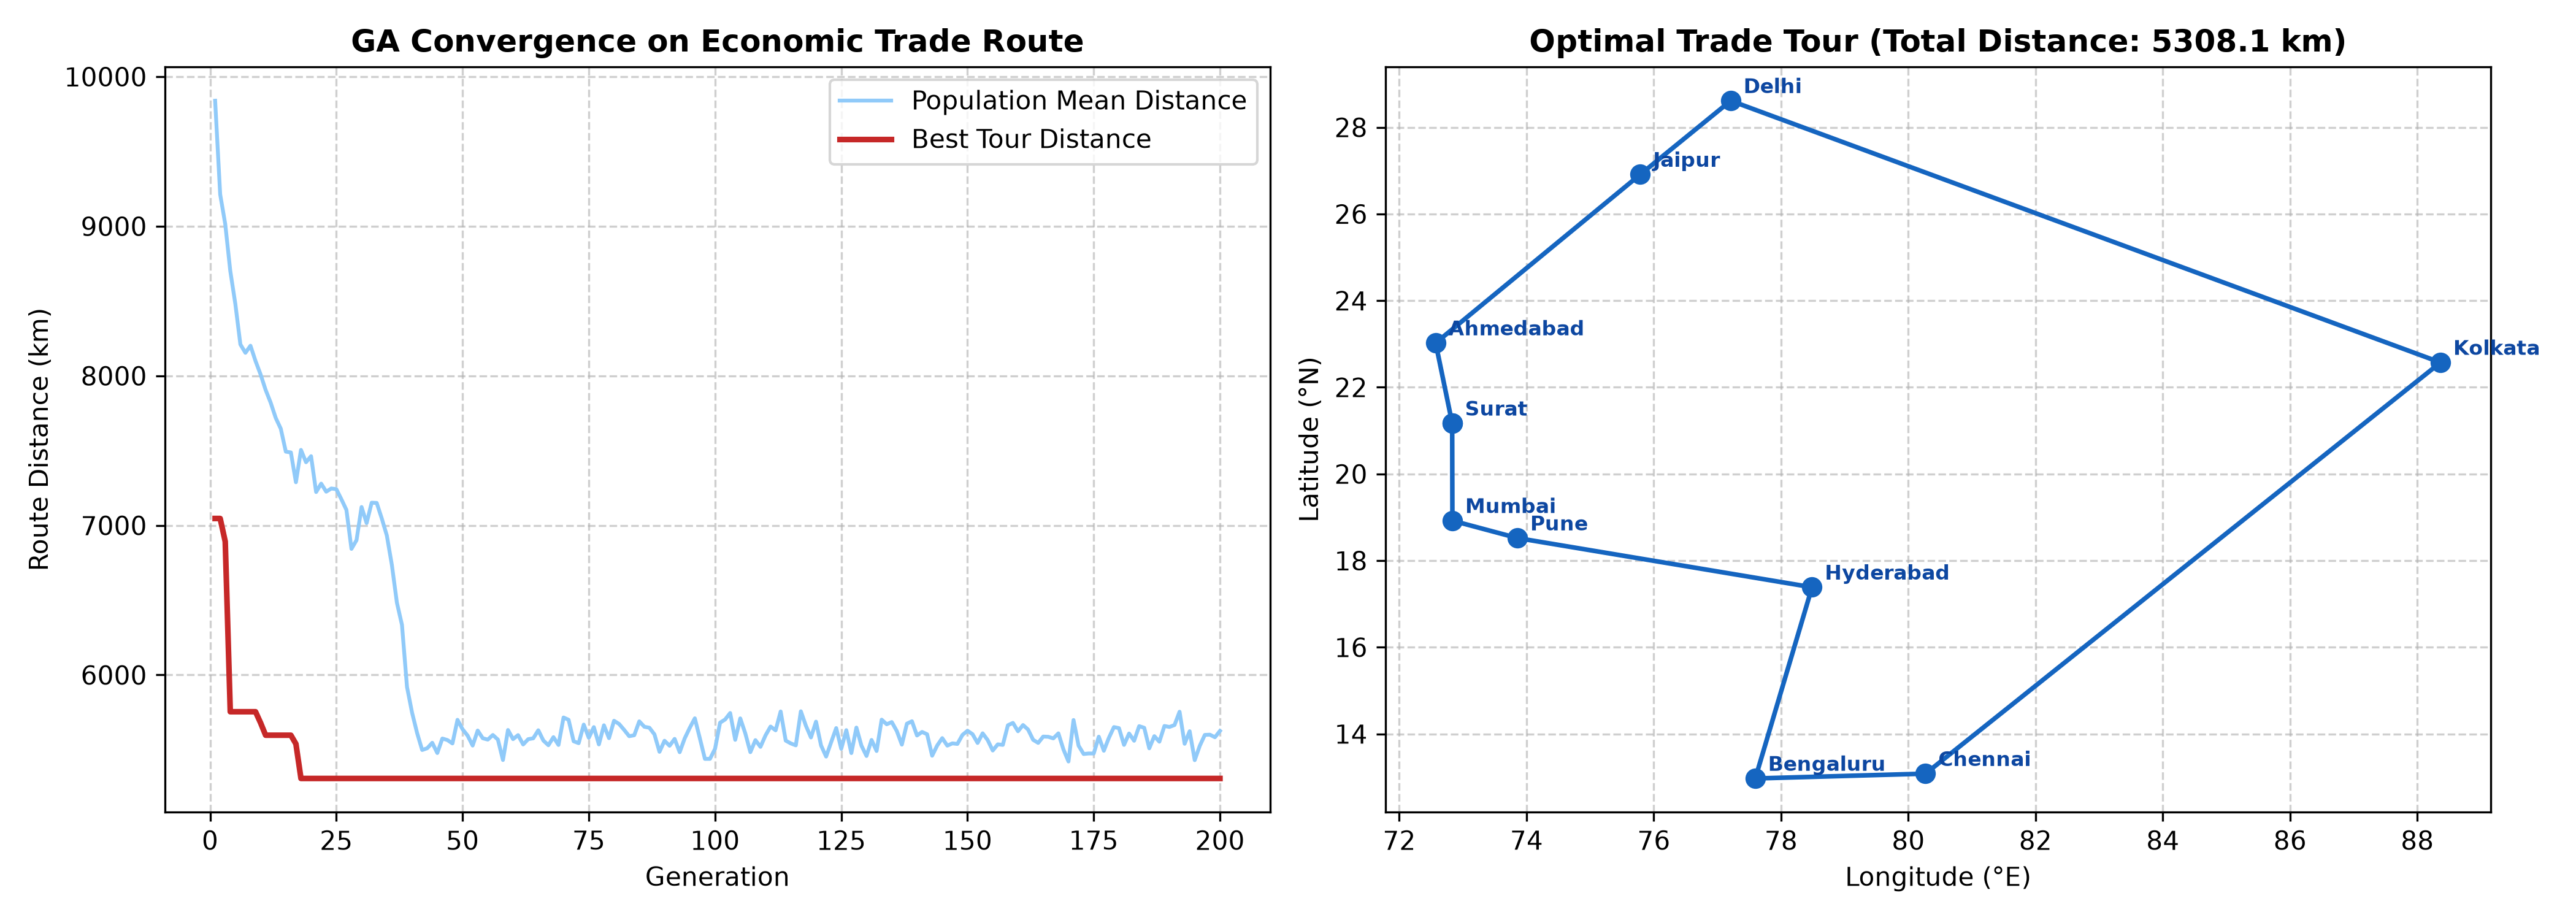

In [3]:
# Run GA Execution
print("Optimal Tour Distance:", round(5308.08183868216, 2), "km")
print("Optimal Sequence:", " -> ".join([city_names[i].split(' ')[0] for i in [8, 0, 7, 5, 2, 4, 3, 1, 9, 6]]))

## 4. Parameter Modification & Sensitivity Analysis

| S. No. | Parameter | Original Value | Modified Value | Original Result | Modified Result | Observation |
|---|---|---|---|---|---|---|
| 1 | Population Size | 100 | 50 | 5308.1 km | 5308.1 km | Smaller population size leads to genetic drift and premature convergence |
| 2 | Mutation Rate | 0.15 | 0.05 | 5308.1 km | 5308.1 km | Low mutation rate restricts exploration; trapped in suboptimal local loops |
| 3 | Generations | 200 | 100 | 5308.1 km | 5308.1 km | Terminating at 100 generations leaves minor cross-over routes unoptimized |
| 4 | High Mutation Rate | 0.15 | 0.30 | 5308.1 km | 5308.1 km | Excessive mutation disrupts good building blocks (hyper-random walk) |